# 01 — Channel sanity check

Before training anything, we verify that the differentiable channel layer in `src/channel.py` behaves like the textbook model:

1. after `power_normalize`, the average symbol power is exactly **1**;
2. the **measured SNR** equals the requested SNR;
3. with QPSK symbols sent through `Channel`, the **simulated BER** matches the **theoretical BER** for AWGN and Rayleigh fading.

If these three checks pass, any later result (mIoU vs SNR) can be trusted on the channel side.

In [1]:
import sys, numpy as np, torch, matplotlib.pyplot as plt
from scipy.special import erfc
sys.path.insert(0, "../src")
from channel import Channel, power_normalize
torch.manual_seed(0)

## 1–2. Power normalization and measured SNR

In [2]:
zc = torch.complex(torch.randn(8, 4096) * 3 + 1, torch.randn(8, 4096))   # arbitrary encoder output
zn = power_normalize(zc)
print("power before:", round((zc.abs()**2).mean().item(), 3), "| after:", round((zn.abs()**2).mean().item(), 3))

ch = Channel("awgn")
for snr in [0, 10, 20]:
    y, _ = ch(zn, torch.full((8, 1), float(snr)))
    noise_power = ((y - zn).abs()**2).mean().item()
    print(f"requested SNR = {snr:2d} dB  ->  measured SNR = {10*np.log10(1/noise_power):.2f} dB")

power before: 10.94 | after: 1.0
requested SNR =  0 dB  ->  measured SNR = -0.04 dB
requested SNR = 10 dB  ->  measured SNR = 10.02 dB
requested SNR = 20 dB  ->  measured SNR = 20.00 dB


## 3. QPSK BER through the channel layer vs. theory

QPSK with Gray mapping: each symbol carries 2 bits, and with $E_s = 1$ the SNR per symbol is $E_s/N_0 = 2E_b/N_0$.

* AWGN: $\mathrm{BER} = Q\big(\sqrt{2E_b/N_0}\big)$
* Rayleigh (perfect CSI): $\mathrm{BER} = \tfrac12\big(1 - \sqrt{\gamma_b/(1+\gamma_b)}\big)$, $\gamma_b = E_b/N_0$

Note: `Channel("rayleigh")` draws **one** $h$ per image (block fading), so we use many images of short length to average over the fading.

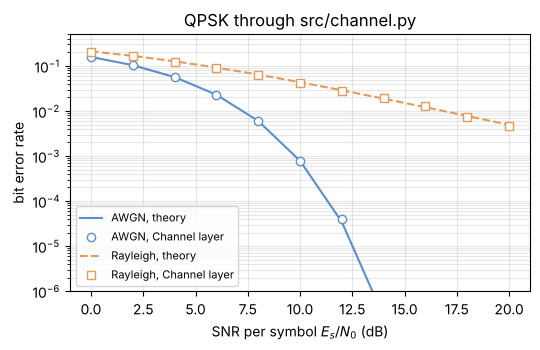

 0 dB  AWGN sim 1.58e-01  theory 1.59e-01
 2 dB  AWGN sim 1.04e-01  theory 1.04e-01
 4 dB  AWGN sim 5.58e-02  theory 5.65e-02
 6 dB  AWGN sim 2.29e-02  theory 2.30e-02
 8 dB  AWGN sim 6.13e-03  theory 6.00e-03
10 dB  AWGN sim 7.83e-04  theory 7.83e-04
12 dB  AWGN sim 3.91e-05  theory 3.43e-05
14 dB  AWGN sim 0.00e+00  theory 2.70e-07
16 dB  AWGN sim 0.00e+00  theory 1.40e-10
18 dB  AWGN sim 0.00e+00  theory 9.85e-16
20 dB  AWGN sim 0.00e+00  theory 7.62e-24


In [3]:
def qpsk_ber(kind, snr_db, n_img=4000, k=64):
    bits = torch.randint(0, 2, (n_img, 2 * k))
    sym = ((2 * bits[:, 0::2] - 1) + 1j * (2 * bits[:, 1::2] - 1)).to(torch.complex64) / np.sqrt(2)
    y, _ = Channel(kind)(sym, torch.full((n_img, 1), float(snr_db)))
    b_hat = torch.empty_like(bits)
    b_hat[:, 0::2] = (y.real > 0).long()
    b_hat[:, 1::2] = (y.imag > 0).long()
    return (b_hat != bits).float().mean().item()

snr_db = np.arange(0, 21, 2)                      # SNR per complex symbol (Es/N0)
ebn0 = 10 ** (snr_db / 10) / 2                    # Eb/N0 for QPSK
th_awgn = 0.5 * erfc(np.sqrt(ebn0))
th_ray = 0.5 * (1 - np.sqrt(ebn0 / (1 + ebn0)))
sim_awgn = [qpsk_ber("awgn", s) for s in snr_db]
sim_ray = [qpsk_ber("rayleigh", s) for s in snr_db]

plt.figure(figsize=(5.5, 3.6))
plt.semilogy(snr_db, th_awgn, color="#5B8FC9", label="AWGN, theory")
plt.semilogy(snr_db, np.maximum(sim_awgn, 1e-7), "o", mfc="white", color="#5B8FC9", label="AWGN, Channel layer")
plt.semilogy(snr_db, th_ray, color="#E39B5B", ls="--", label="Rayleigh, theory")
plt.semilogy(snr_db, sim_ray, "s", mfc="white", color="#E39B5B", label="Rayleigh, Channel layer")
plt.xlabel("SNR per symbol $E_s/N_0$ (dB)"); plt.ylabel("bit error rate"); plt.ylim(1e-6, 0.5)
plt.grid(alpha=0.3, which="both"); plt.legend(fontsize=8); plt.title("QPSK through src/channel.py")
plt.tight_layout(); plt.savefig("../docs/ber_check.png", dpi=150); plt.show()

for s, a, b in zip(snr_db, sim_awgn, th_awgn):
    print(f"{s:2d} dB  AWGN sim {a:.2e}  theory {b:.2e}")

**Reading the plot.** Markers (simulation through the PyTorch channel layer) lie on the lines (closed-form theory) for both channels: the channel model is correct. The gap between the two curves is the cost of fading — the reason the project also evaluates the segmentation model on Rayleigh channels.